# Multimodal — Klasifikasi (teks + kolom angka)
**Kapan dipakai:** tiap baris punya kolom teks (judul, deskripsi, ulasan) DAN kolom angka
(harga, tahun, jumlah), dan diminta menebak kelas.

**Idenya:** teks diubah jadi angka dengan TF-IDF (bobot tiap kata), kolom angka diisi
median lalu disamakan skalanya. Keduanya digabung jadi satu tabel, lalu model sklearn biasa.
`ColumnTransformer` mengatur "kolom mana diolah dengan cara apa".

**Langkah:**
1. Baca data, split train/validasi.
2. Olah teks + angka, latih model, evaluasi F1.
3. Latih ulang di semua data, buat submission.

**Data demo:** judul film (`title`) + tahun rilis (`release_year`), target biner `target`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/multimodal/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"

ID_COL = "id"
TARGET_COL = "target"
TEXT_COL = "title"
NUMBER_COLS = ["release_year"]
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print(train.shape, test.shape)
print(train.isna().sum())
print(train[TARGET_COL].value_counts(normalize=True))
train.head()

(1331, 4) (333, 3)
id              0
title           0
release_year    1
target          0
dtype: int64
target
0    0.569497
1    0.430503
Name: proportion, dtype: float64


,id,title,release_year,target
0,995,"Kiss Me, Guido",1997.0,0
1,1244,Metro,1997.0,0
2,539,Mouse Hunt,1997.0,0
3,63,"Santa Clause, The",1994.0,0
4,864,My Fellow Americans,1996.0,0


## Langkah 1 — split train/validasi

In [4]:
X = train[[TEXT_COL] + NUMBER_COLS]
y = train[TARGET_COL]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y,
                                                  random_state=SEED)

## Langkah 2 — olah teks + angka, lalu model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [5]:
text_steps = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
number_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
preprocess = ColumnTransformer([
    ("text", text_steps, TEXT_COL),
    ("number", number_steps, NUMBER_COLS),
])

model = LogisticRegression(C=1.0, max_iter=2000)
# model = LinearSVC(C=0.5)                     # sering paling kuat untuk teks
# model = RandomForestClassifier(n_estimators=500, random_state=SEED)
# model = LGBMClassifier(n_estimators=300, learning_rate=0.03, random_state=SEED, verbose=-1)

pipeline = make_pipeline(preprocess, model)
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['title','release_year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('number', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere 

## Evaluasi di data validasi

F1 macro: 0.4812


              precision    recall  f1-score   support

           0       0.58      0.86      0.69       152
           1       0.50      0.18      0.27       115

    accuracy                           0.57       267
   macro avg       0.54      0.52      0.48       267
weighted avg       0.55      0.57      0.51       267



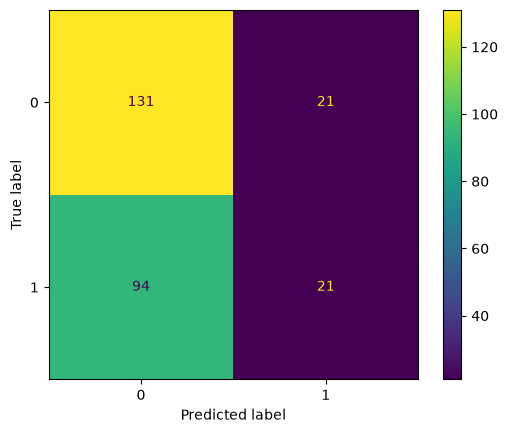

In [6]:
pred_val = pipeline.predict(X_val)
print("F1 macro:", round(f1_score(y_val, pred_val, average="macro"), 4))
print(classification_report(y_val, pred_val))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val)
plt.show()

## Langkah 3 — latih ulang di semua data + submission

In [7]:
pipeline.fit(X, y)
predictions = pipeline.predict(test[[TEXT_COL] + NUMBER_COLS])

submission = pd.DataFrame()
submission["id"] = test[ID_COL]
submission["target"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,target
0,826,0
1,923,1
2,1070,0
3,1220,0
4,607,0
